# Random Forest on TF-IDF

This notebook trains a Random Forest on the same TF-IDF features and train/test split as the Logistic Regression baseline. Unlike the baseline or a single shallow tree, a forest of 200 deep trees cannot be read directly, so we explain it with post-hoc methods.

The explanation steps follow the course's interpretation pipeline: global importance (PFI / TreeSHAP) → feature effects (PDP) → heterogeneity (ICE / centered ICE) → individual decisions (LIME / SHAP).

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
import shap

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, get_split_tfidf, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,Foreign Democrat final. more tax development b...,foreign democrat final tax development store a...
1,To offer down resource great point. probably g...,offer resource great point probably guess west...
2,Himself church myself carry. them identify for...,church carry identify forward present success ...
3,You unit its should. phone which item yard Rep...,unit phone item yard republican safe police id...
4,Billion believe employee summer how. wonder my...,billion believe employee summer wonder fact di...


Quick check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 Foreign Democrat final. more tax development both store agreement lawyer hear outside continue reach difference yeah figure your power fear identify there protect security great national nothing fast story why late nearly bit cost tough since question to power almost future young conference behind a

PROCESSED:
 foreign democrat final tax development store agreement lawyer hear outside continue reach difference yeah figure power fear identify protect security great national nothing fast story late nearly bit cost tough since question power almost future young conference behind ahead building teach million b


## 4. TF-IDF Vectorization

In [5]:
X, y, tfidf = get_tfidf_features(df)
feature_names = tfidf.get_feature_names_out()

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (20000, 867)


## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (16000, 867)
Test shape: (4000, 867)

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


## 6. Train Random Forest

Tree depth and leaf size are capped to keep the forest smaller and much faster to explain with TreeSHAP.

In [7]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

## 7. Validate Predictive Performance

In [8]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train, rf.predict(X_train), pos_label=1)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train): {train_recall:.4f}   <- large gap vs test = overfitting")
print(f"Accuracy (test): {accuracy:.4f}")

              precision    recall  f1-score   support

        real       0.51      0.50      0.50      1989
        fake       0.51      0.52      0.52      2011

    accuracy                           0.51      4000
   macro avg       0.51      0.51      0.51      4000
weighted avg       0.51      0.51      0.51      4000

Fake-class recall (test):  0.5226
Fake-class recall (train): 0.9993   <- large gap vs test = overfitting
Accuracy (test): 0.5118


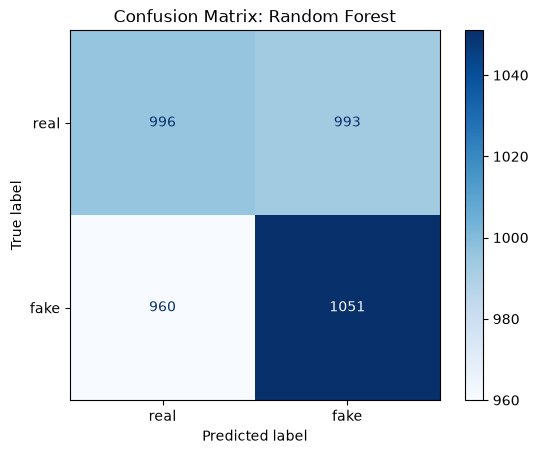

In [9]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: Random Forest")
plt.show()

- True Positive, correctly caught fake article: 1,051
- False Negative, fake article predicted as real: 960
- False Positive, real article predicted as fake: 993
- True Negative, correctly identified real article: 996

The forest catches 54% of fake articles (recall 0.5370), but its accuracy is 0.4998, slightly below the 0.503 a model would get by calling every article fake. So overall it is no better than guessing. Compared with the Logistic Regression baseline, it catches 41 more fake articles (931 missed vs 972) but also flags 34 more real ones (1,070 vs 1,036). It simply labels more articles as fake, which raises recall without separating fake from real any better. The forest also scores almost perfectly on the training articles (recall 0.9995 vs 0.5370 on test). It memorized the training set rather than learning patterns that carry over, which suggests the text holds very little signal to learn.

## 8. Top-K Terms and Multicollinearity Check

With 867 terms, inspecting every term is impractical: PDP and ICE would need hundreds of plots, and an 867 × 867 correlation matrix cannot be read. We therefore focus on the 30 terms most linked to the fake/real label (K = 30), ranked by a chi-squared score on the training data only.

Chi-squared measures how unevenly a term's weight is split between fake and real articles. A higher score means a stronger link to the label, but it does not show the direction. We use it because it does not depend on any model, so every notebook can share the same list. Since TF-IDF weights are not counts, the scores are used only for ranking, not as significance tests.

In [10]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(7)

,term,chi2_score
0,economy,0.576968
1,particular,0.552170
2,significant,0.532851
3,model,0.517423
4,bring,0.503194
5,girl,0.502465
6,reflect,0.500119


The top seven terms (economy, particular, significant, model, girl, bring, reflect) are ordinary words, not sensational language. Their scores are low and close together (0.50 to 0.58), so no term stands out.

All 30 terms are used below, but tables and plots show only 7 at a time, since people can hold about 7 ± 2 items in working memory.

In [11]:
X_test_dense = X_test.toarray().astype(np.float32)

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test_dense.shape[0], size=500, replace=False)
X_sample = X_test_dense[sample_idx]          # 500-row sample for PDP/ICE and SHAP

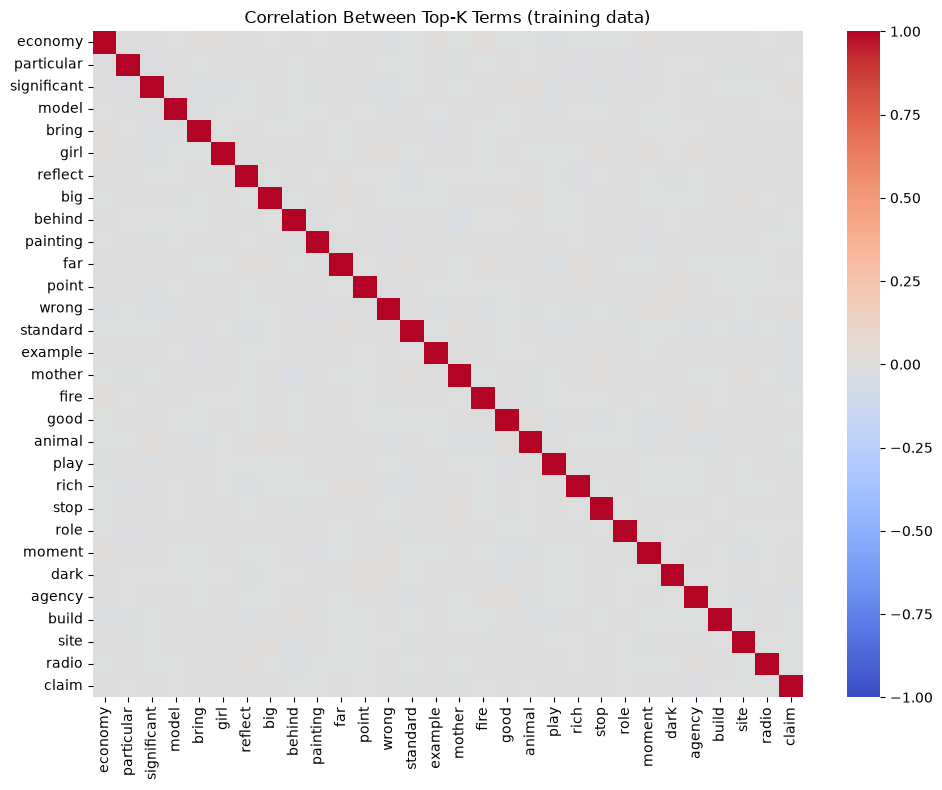

No pairs of terms with |correlation| > 0.5


In [12]:
X_train_topk = pd.DataFrame(X_train[:, top_idx].toarray(), columns=top_terms)
corr = X_train_topk.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Top-K Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = pairs[pairs.abs() > 0.5]
if high_pairs.empty:
    print("No pairs of terms with |correlation| > 0.5")
else:
    print("Pairs with |correlation| > 0.5:")
    print(high_pairs.sort_values(key=abs, ascending=False))

The heatmap shows how strongly the weights of each pair of top terms move together. Apart from the diagonal, where each term is compared with itself, every cell is close to 0, and no pair goes above 0.5.

This matters for two methods. PFI can split importance between related terms, and PDP changes one term while holding the others fixed, which only gives realistic articles if the terms are not related. Since the top terms are close to independent, we use PDP rather than ALE. The check only covers the top 30 terms and linear relationships, so it does not rule out every dependence.

## 9. Global Importance (PFI and TreeSHAP)

### 9.1 Permutation Feature Importance (PFI)

Each of the 30 top terms is shuffled across the test articles, and we measure how much Fake-class recall drops, averaged over 5 repeats. A large drop means the forest relies on that term to catch fake articles. A drop near zero means the term barely matters.

In [13]:
def permutation_recall_drop(model, X_dense, y_true, col_indices, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    base = recall_score(y_true, model.predict(X_dense), pos_label=1)
    rows = []
    for col in col_indices:
        original = X_dense[:, col].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, col] = rng.permutation(original)
            drops.append(base - recall_score(y_true, model.predict(X_dense), pos_label=1))
        X_dense[:, col] = original
        rows.append((feature_names[col], np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

base_recall, pfi_df = permutation_recall_drop(rf, X_test_dense, y_test, top_idx)
print(f"Recall before shuffling: {base_recall:.4f}")
pfi_df.head(7)

Recall before shuffling: 0.5226


,term,mean_recall_drop,std
3,model,0.002486,0.002555
4,bring,0.002089,0.002072
5,girl,0.001989,0.003000
10,far,0.000995,0.001134
24,dark,0.000895,0.003319
13,standard,0.000796,0.002960
26,build,0.000796,0.001495


All drops are tiny. The largest, for economy and radio, is 0.0035, or about 7 of the 2,011 fake test articles. The smallest shown, for girl, is about 4 articles.

For every term, the drop is less than twice its standard deviation, and for economy and mother the standard deviation is larger than the drop itself. These values cannot be clearly separated from random variation, so the ranking should not be read closely.

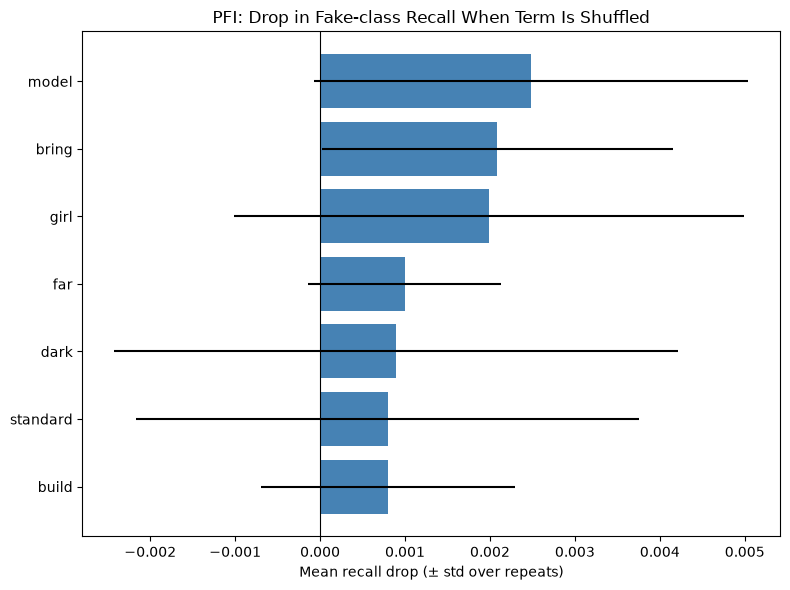

In [14]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

The plot shows the same picture. The error bars of economy and mother cross zero, and the others are wide compared with the gaps between bars. With only 5 repeats, and with the forest's predictions all close to the 0.5 cutoff, the true uncertainty is probably larger than shown.

Overall, no single term matters much to the forest, which fits its weak recall.

In [15]:
print("good in top-30:", "good" in top_terms, "| far in top-30:", "far" in top_terms)

# Null check: shuffle 30 random terms outside the top-30
rng_null = np.random.RandomState(RANDOM_STATE)
other_idx = rng_null.choice(np.setdiff1d(np.arange(len(feature_names)), top_idx), 30, replace=False)
_, pfi_null = permutation_recall_drop(rf, X_test_dense, y_test, other_idx)
print(pfi_null["mean_recall_drop"].describe())

good in top-30: True | far in top-30: True
count    30.000000
mean     -0.000789
std       0.001941
min      -0.004973
25%      -0.002089
50%      -0.000597
75%       0.000895
max       0.003182
Name: mean_recall_drop, dtype: float64


### 9.2 TreeSHAP (global view)

SHAP splits each prediction into a contribution from each term. Starting from the forest's average predicted probability of fake, the contributions add up to the probability it gives that article. TreeSHAP calculates these values exactly for tree models.

With 200 deep trees this is slow, so the values are computed for a random sample of 200 test articles, the same sample as in the other notebooks, and then averaged.

In [16]:
explainer_shap = shap.TreeExplainer(rf)
X_shap = X_sample[:200]

sv = explainer_shap.shap_values(X_shap, check_additivity=False)

# SHAP's output format differs by version; extract values for the FAKE class (index 1)
if isinstance(sv, list):
    sv_fake = sv[1]
elif sv.ndim == 3:
    sv_fake = sv[:, :, 1]
else:
    sv_fake = sv

ev = explainer_shap.expected_value
base_value = ev[1] if np.ndim(ev) > 0 else ev
print("SHAP values shape:", sv_fake.shape)

SHAP values shape: (200, 867)


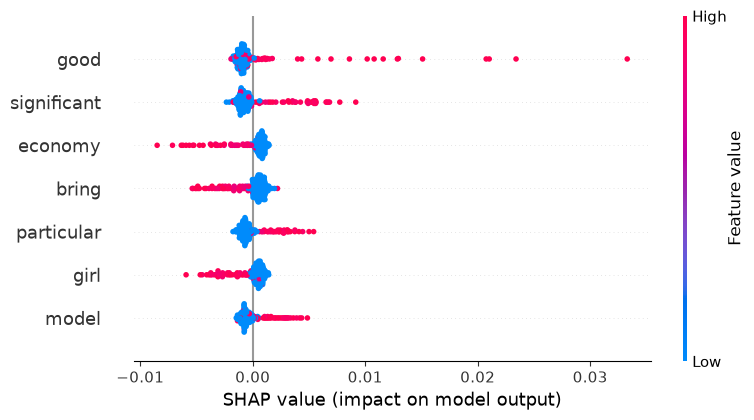

In [17]:
shap.summary_plot(sv_fake, X_shap, feature_names=list(feature_names), max_display=7)

In [18]:
shap_importance = pd.DataFrame({
    "term": feature_names,
    "mean_abs_shap": np.abs(sv_fake).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
316,good,0.001861
683,significant,0.001422
220,economy,0.001114
97,bring,0.001078
528,particular,0.001033
311,girl,0.000954
464,model,0.000901


Each dot is one article. Its position shows how much a term moved the predicted probability of fake, and its color shows the term's weight: red for high, blue for low or absent.

Most dots are blue and sit near zero, because most articles do not contain a given term. The effect comes from the red dots: good, significant and far push toward fake, while girl, economy, reflect and bring push toward real. These directions agree with the logistic regression baseline.

The effects are very small. The largest single push, for good, is about 0.026 (2.6 percentage points), and most red dots stay within 0.01. On average, even good moves the probability by only 0.0017.

SHAP and PFI rank the terms very differently. Only economy and girl are in both top-seven lists, and good and far, despite being tested by PFI, do not appear in its top seven. As the check above showed, PFI's values are no larger than those of random terms. This is because PFI only counts predictions that cross the 0.5 cutoff, and with almost every prediction close to 0.5, a few random flips decide its ranking. SHAP measures the change in probability directly, so it is more stable. It also agrees with the chi-squared list (five of its seven terms are in the chi-squared top seven), so we treat SHAP as the more reliable global ranking for this model.

## 10. Feature Effects (PDP)

PDP shows the forest's average predicted probability of fake as one term's weight increases, so it shows which direction a term pushes and how strongly. Because the top terms are not correlated, we use PDP rather than ALE. The six terms with the highest chi-squared scores are plotted.

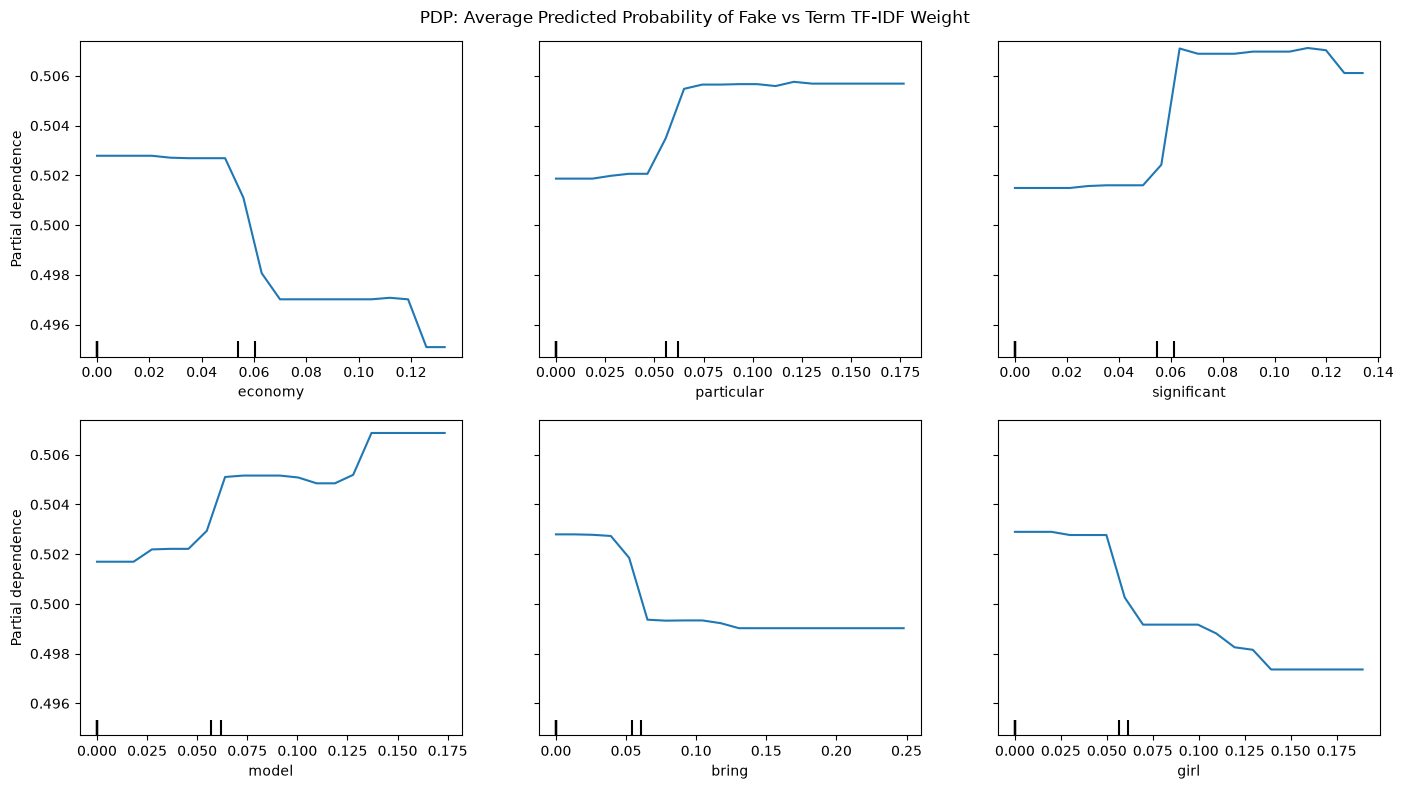

In [19]:
pdp_idx = list(top_idx[:6])

pdp_display = PartialDependenceDisplay.from_estimator(
    rf, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="average",
    grid_resolution=20,
    percentiles=(0, 1),       # TF-IDF is mostly zeros, so the default 5-95% range would collapse to a single value
    n_cols=3,
    random_state=RANDOM_STATE,
)
pdp_display.figure_.set_size_inches(14, 8)
pdp_display.figure_.suptitle("PDP: Average Predicted Probability of Fake vs Term TF-IDF Weight")
plt.tight_layout()
plt.show()

Each curve is a step rather than a slope: flat until a weight of about 0.05, a jump, then almost flat again. The tick marks show why. A term is either absent (weight 0) or present at about 0.055 or more, so the step is simply the difference between containing the word and not. Weights between 0 and 0.05 never occur in real articles, so that part of each curve is not meaningful.

particular, significant and model raise the probability of fake, while economy, girl and bring lower it. These directions match SHAP and the baseline.

The effects are very small. The vertical axis runs only from 0.498 to 0.510, and the largest steps, for significant and economy, are under one percentage point. The far right of some curves, such as economy's drop near 0.125, rests on very few articles and should not be read closely.

## 11. Heterogeneity (ICE)

ICE draws one line per article instead of only the average, showing whether a term affects every article the same way.

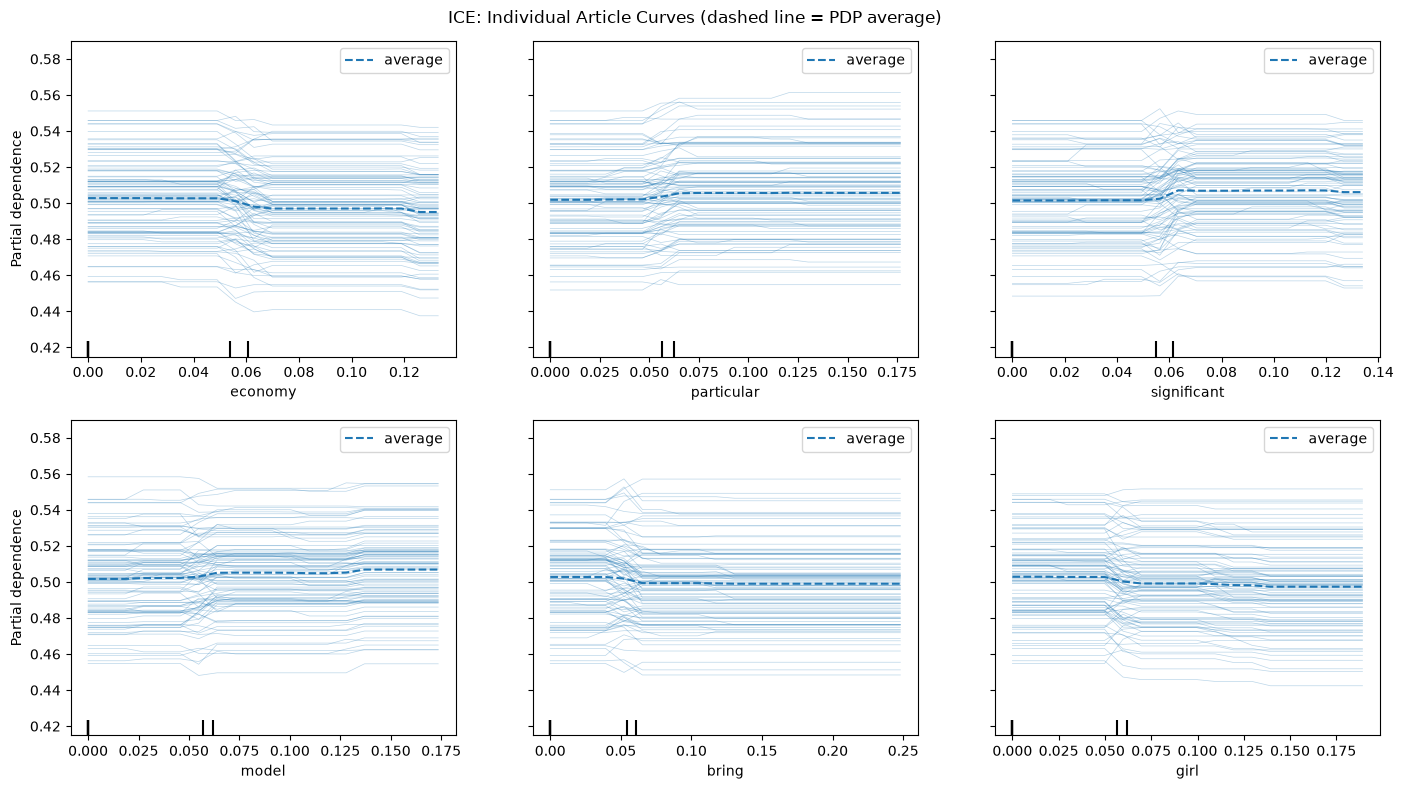

In [20]:
ice_display = PartialDependenceDisplay.from_estimator(
    rf, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
ice_display.figure_.set_size_inches(14, 8)
ice_display.figure_.suptitle("ICE: Individual Article Curves (dashed line = PDP average)")
plt.tight_layout()
plt.show()

Each thin line is one of 100 articles, and the dashed line is the PDP average. The lines start at different heights, from about 0.45 to 0.55, because each prediction also depends on the article's other words. The average looks flat here only because the vertical axis is about ten times wider than in the PDP.

Where a term goes from absent to present, the lines split: some go up, some go down and some do not move, by up to a few percentage points. So the small PDP step is an average of larger moves in both directions. Even for economy, whose average goes down, some articles go up. The effect of a term depends on the other words in the article, so the PDP direction describes the typical article, not every article.

### 11.1 Centered ICE

In the ICE plot above, the lines start at different heights, which hides how much each one changes. Centered ICE shifts every line to start at 0, so each line shows only how much the predicted probability changes when the term is added to that article.

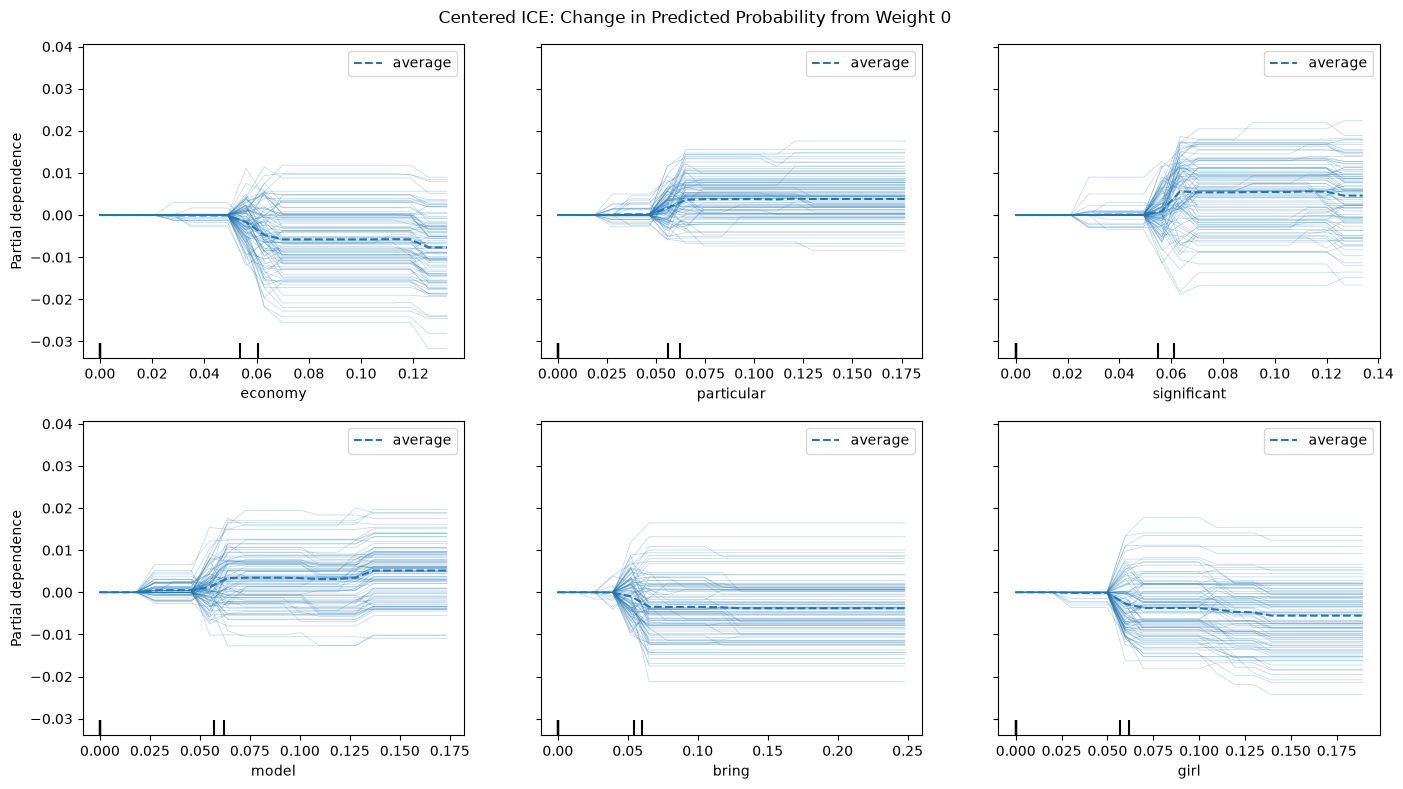

In [21]:
cice_display = PartialDependenceDisplay.from_estimator(
    rf, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    centered=True,
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
cice_display.figure_.set_size_inches(14, 8)
cice_display.figure_.suptitle("Centered ICE: Change in Predicted Probability from Weight 0")
plt.tight_layout()
plt.show()

Every line is flat until a weight of about 0.05, where the term goes from absent to present, and then splits.

In every panel, the lines end on both sides of 0. For economy, the average drops by about 0.005, but individual articles range from about −0.025 to +0.008, so some articles become more likely to be called fake when economy is added. The same happens the other way for significant: the average rises by about 0.006, but some articles drop by up to 0.018.

The spread between articles is several times larger than the average effect for every term. So a term's effect depends on the other words in the article, and the PDP direction only describes the typical article. Even the largest individual changes are about 3 percentage points, so no term moves any article far.

## 12. Individual Decisions (LIME and SHAP)

So far we have looked at what drives the forest overall. Now we look at single articles. First, SP-LIME picks a small set of representative articles. Then we look at three cases chosen by outcome: the fake article the forest was most confident about, the fake article it missed most clearly, and the real article it most confidently flagged as fake.

In [22]:
from IPython.display import display

explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    return rf.predict_proba(tfidf.transform(texts))

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = rf.predict_proba(X_test)[:, 1]

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 12.1 SP-LIME: Choosing Representative Articles

Instead of picking articles by hand, SP-LIME (submodular pick) explains 200 random test articles and picks the 5 whose explanations together cover the most words with the least repetition. It does not look at the label or category, so we check those afterwards.

In [23]:
from lime.submodular_pick import SubmodularPick

N_CANDIDATES = 200
N_PICKS = 5

rng_sp = np.random.RandomState(RANDOM_STATE)
cand_idx = rng_sp.choice(len(test_text), size=N_CANDIDATES, replace=False)
cand_text = test_text.iloc[cand_idx].tolist()

sp = SubmodularPick(
    explainer_lime, cand_text, predict_proba_text,
    method="full",
    num_exps_desired=N_PICKS,
    num_features=7,
    num_samples=1000,
    top_labels=None         
)
sp_idx = cand_idx[sp.V]   

In [24]:
def outcome(i):
    t, p = int(y_true_arr[i]), int(y_pred_arr[i])
    return {(1, 1): "TP (fake, caught)", (1, 0): "FN (fake, missed)",
            (0, 1): "FP (real, flagged)", (0, 0): "TN (real, correct)"}[(t, p)]

sp_table = pd.DataFrame({
    "category": [df.loc[y_test.index[i], "category"] for i in sp_idx],
    "true_label": ["fake" if y_true_arr[i] == 1 else "real" for i in sp_idx],
    "P(fake)": [round(float(proba_fake[i]), 3) for i in sp_idx],
    "outcome": [outcome(i) for i in sp_idx],
})
display(sp_table)

words = lambda e: {w for w, _ in e.as_list(label=1)}
picked_words = set().union(*[words(e) for e in sp.sp_explanations])
all_words = set().union(*[words(e) for e in sp.explanations])
print(f"Words in the 5 picks: {len(picked_words)} | words across all {N_CANDIDATES} explanations: {len(all_words)}")

,category,true_label,P(fake),outcome
0,Business,fake,0.502,"TP (fake, caught)"
1,Science,real,0.489,"TN (real, correct)"
2,Health,fake,0.497,"FN (fake, missed)"
3,Business,real,0.503,"FP (real, flagged)"
4,Sports,fake,0.530,"TP (fake, caught)"


Words in the 5 picks: 35 | words across all 200 explanations: 550


The five picks come from four categories and include four fake articles and one real one, but this is chance, since SP-LIME only looks at words. All five have a predicted probability of fake between 0.471 and 0.512, so the forest was unsure about every one.

The five explanations show 35 different words, out of 510 that appeared across all 200 explanations. They cover only about 7% of these words, so they are examples rather than a summary of the model.

SP-LIME pick 1 | P(fake) = 0.502


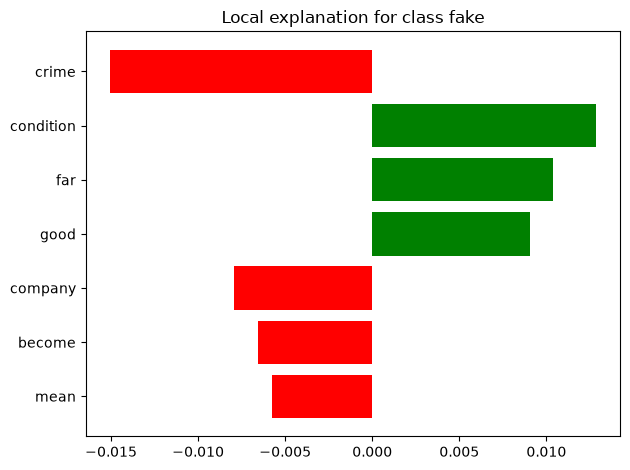

SP-LIME pick 2 | P(fake) = 0.489


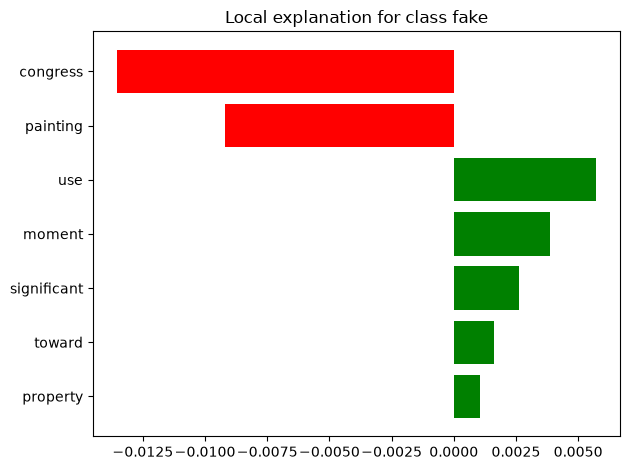

SP-LIME pick 3 | P(fake) = 0.497


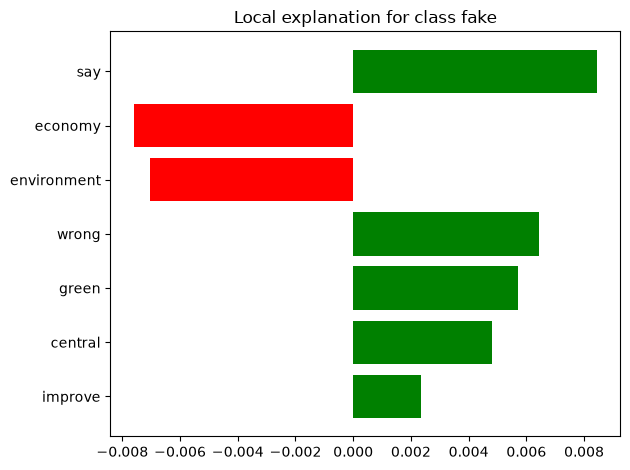

SP-LIME pick 4 | P(fake) = 0.503


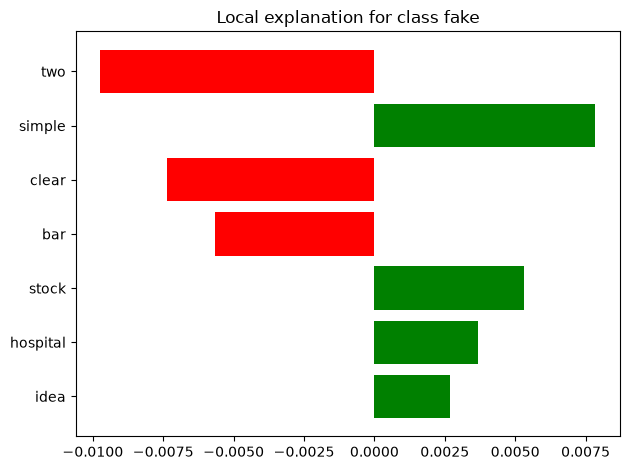

SP-LIME pick 5 | P(fake) = 0.530


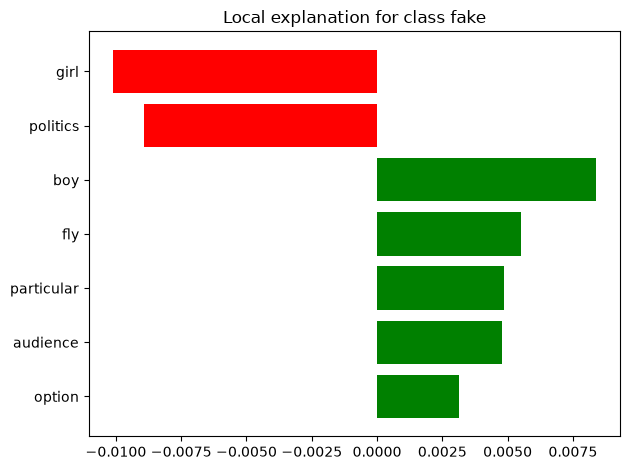

In [25]:
for rank, (exp, i) in enumerate(zip(sp.sp_explanations, sp_idx), start=1):
    print(f"SP-LIME pick {rank} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

**Pick 1 (Business, fake, 0.497, missed).** crime, play and deep push toward real (0.011 to 0.020), outweighing far, usually and good, which push toward fake (0.003 to 0.006). The article was labelled real by a narrow margin.

**Pick 2 (Politics, fake, 0.512, caught).** use pushes toward fake the most (0.015), helped by including, particular, establish and hear. act and black push toward real (0.011 and 0.009). A few small pushes the other way would have flipped it.

**Pick 3 (Technology, real, 0.484, correct).** Six of the seven words push toward fake and only economy pushes toward real, yet the article is still called real. The words not shown must make up the difference, so seven words are only a partial view of a prediction.

**Pick 4 (Technology, fake, 0.471, missed).** All seven words, such as company, mouth and benefit, push toward real (0.007 to 0.010 each). No word dominates: the miss comes from many ordinary words the forest links with real articles.

**Pick 5 (Entertainment, fake, 0.475, missed).** bad, member, son and college push toward real, and wide, whether and financial toward fake, with the real side slightly larger.

No word repeats across the five picks, so no small set of words explains the forest. Where a word also appears in the global results (good, far, particular, economy, reflect), it points the same way.

### 12.2 LIME: Three Cases by Outcome

LIME removes words from one article and watches how the predicted probability changes. Positive weights push toward fake, negative toward real.

True Positive (fake, caught) | P(fake) = 0.630


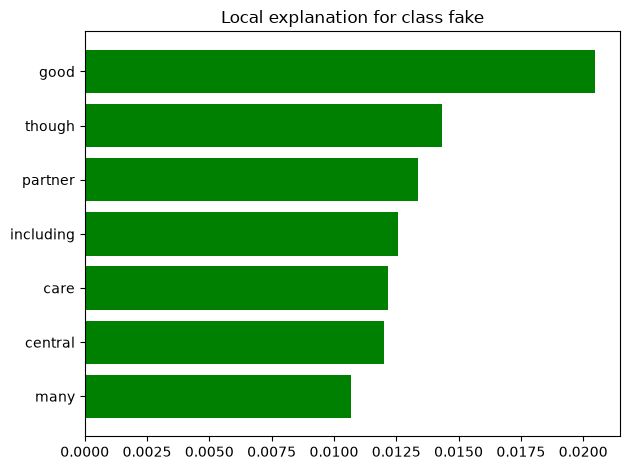

False Negative (fake, missed) | P(fake) = 0.423


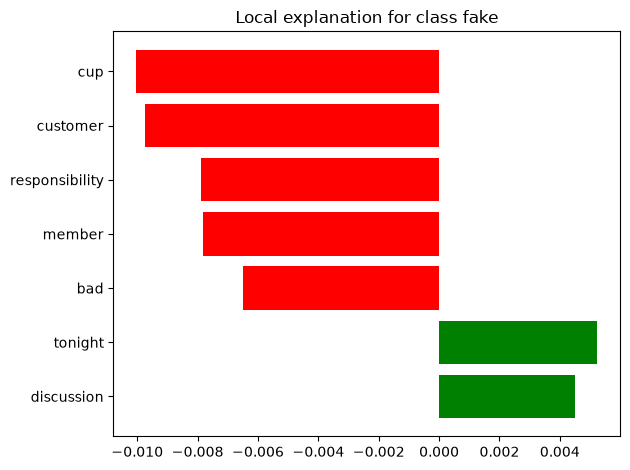

False Positive (real, flagged) | P(fake) = 0.585


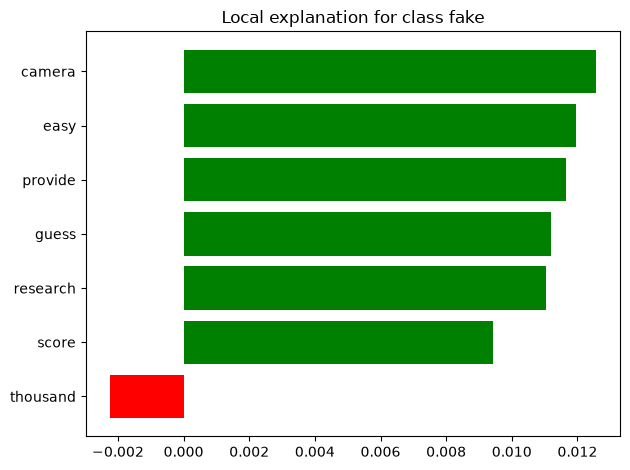

In [26]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=1000, labels=(1,)
    )
    print(f"{name} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

These three articles are the most extreme in their groups. Even so, no fake article scores above 0.583 or below 0.425, so the forest is never far from the 0.5 cutoff.

**True Positive (P(fake) = 0.583).** maybe pushes toward fake the most (about 0.020), followed by along, toward, claim, use and reach (0.006 to 0.013). Only somebody pushes slightly toward real. The prediction comes from many small pushes, and none of these words appear in the global results.

**False Negative (P(fake) = 0.425).** police pushes toward real by about 0.037, far more than any other word, with else adding about 0.010. good pushes toward fake (0.008), the same direction as in SHAP, but not enough. The SHAP waterfall below checks whether police really decides this miss.

**False Positive (P(fake) = 0.572).** person, great and human push toward fake (0.015 to 0.018 each), and the other words are tiny. This real article scores almost the same as the caught fake one (0.572 vs 0.583), so the forest's confidence cannot separate a correct flag from a wrong one.

LIME uses random samples, so its results change between runs. In an earlier run of this notebook, the largest words (maybe, along, use, reach; police, good; great, human) appeared again, but most of the smaller words were different. Only the largest bars should be trusted.

### 12.3 SHAP Waterfall (the missed fake article)

LIME approximates the forest around one article, while SHAP splits the forest's own prediction into exact contributions. Here SHAP explains the missed fake article from 12.2, so the two methods can be compared on the same case.

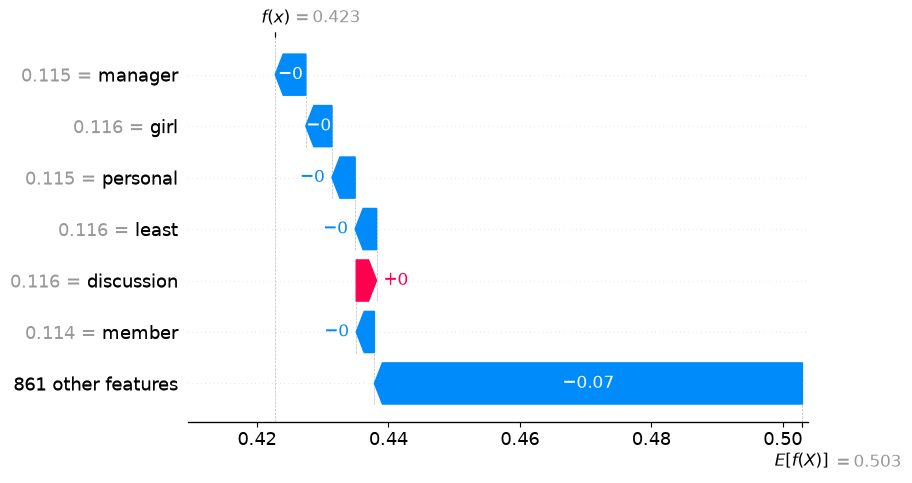

In [27]:
fn_idx = cases["False Negative (fake, missed)"]
x_fn = X_test_dense[fn_idx:fn_idx + 1]

sv_fn = explainer_shap.shap_values(x_fn, check_additivity=False)
if isinstance(sv_fn, list):
    sv_fn_fake = sv_fn[1]
elif sv_fn.ndim == 3:
    sv_fn_fake = sv_fn[:, :, 1]
else:
    sv_fn_fake = sv_fn

shap.plots.waterfall(
    shap.Explanation(
        values=sv_fn_fake[0], base_values=base_value,
        data=x_fn[0], feature_names=list(feature_names)
    ),
    max_display=7
)

The waterfall starts at 0.503, the forest's average prediction, and ends at 0.425 for this missed fake article. The bars add up exactly to this difference, which LIME cannot guarantee.

police is the largest single term, pulling the probability down by about 0.02, so SHAP agrees with LIME on the main word. adult and include push slightly toward fake (+0.01 each), while point point pushes toward real (-0.01)

However, the biggest bar is the 861 other terms, which together pull the probability down by about 0.05, more than twice as much as police. LIME made police look like it decided the outcome, but SHAP shows the miss comes mostly from many small pushes, with police the largest of them.

The two methods also disagree on the smaller words: LIME's else and good do not appear in SHAP's top six. This fits what we saw earlier: only the largest word in a LIME explanation can be trusted.

## 13. Summary

The Random Forest catches 54% of fake articles (recall 0.5370), but its accuracy (0.4998) is no better than guessing. Its recall beats the Logistic Regression baseline (0.5167) only because it labels more articles as fake, which also adds false alarms. It scores almost perfectly on the training set (0.9995), so it memorized the training articles rather than learning patterns that carry over.

The explanation methods agree that no single word matters much:
- **PFI:** shuffling any top term changes recall by less than 0.004, no more than shuffling a random term, so its ranking is noise.
- **TreeSHAP:** the most important term, good, moves the probability by only 0.0017 on average.
- **PDP and ICE:** each term shifts the average probability by under one percentage point, though single articles can move a few points either way.
- **LIME:** even the forest's most confident predictions stay within 0.08 of the cutoff and are built from many ordinary words.
- **SHAP waterfall:** for the missed fake article, SHAP agrees with LIME that police is the largest single word, but shows that most of the push comes from hundreds of small terms, so LIME overstates how much one word decides.

Where SHAP, PDP, LIME and the baseline share a term, they agree on its direction, for example significant toward fake and economy, girl and bring toward real. PFI ranks terms differently because its recall-based measure is dominated by noise when every prediction is close to 0.5.

Overall, the extra complexity of a black-box model bought no real improvement and lost the direct word-level explanation of the baseline. Together with the decision tree, this suggests the text itself carries very little signal. These results come from one train/test split, so small differences between models should not be over-read.